# BÀI 1: XÂY DỰNG VÀ ĐÁNH GIÁ MẠNG MLP TRÊN DỮ LIỆU `make_moons`

### Mục tiêu thực hành:
1. **Hiểu nguyên lý hoạt động của MLP (Multi-Layer Perceptron)**: Cơ chế lan truyền xuôi (forward pass), hàm kích hoạt phi tuyến tính (activation function), lan truyền ngược (backpropagation) và tối ưu hóa trọng số.
2. **Khảo sát ảnh hưởng của số lượng neuron trong tầng ẩn**: Huấn luyện các mô hình MLP với kích thước tầng ẩn: **8, 32, 64, 128** neurons.
3. **So sánh toàn diện các chỉ số**:
   - Training Loss & Validation Loss.
   - Training Accuracy & Validation Accuracy.
   - Validation Macro-F1 Score.
   - Tổng số lượng tham số học được (Trainable Parameters).
   - Thời gian huấn luyện (Training Latency).
4. **Trực quan hóa sinh động**:
   - Đồ thị ranh giới phân loại 2D (Decision Boundaries).
   - Đường cong học tập (Learning Curves) theo từng epoch.
   - Biểu đồ so sánh dạng cột (Performance & Cost Bar Charts).
5. **Đưa ra nhận xét định lượng và định tính** về mối quan hệ giữa dung lượng mô hình (capacity), hiện tượng underfitting/overfitting và chi phí tính toán.



## Bước 1: Thiết lập môi trường và cấu hình Reproducibility
Chúng ta sẽ import các phương thức dùng chung từ `srcs.utilities` và `srcs.libraries`, thiết lập random seed cố định để đảm bảo kết quả hoàn toàn có thể tái lập (reproducible), và tự động nhận diện phần cứng GPU CUDA hoặc CPU.



In [1]:
import sys
import os
import matplotlib.pyplot as plt
import torch

# Đảm bảo đường dẫn gốc của project có trong sys.path
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), "../.."))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from srcs.libraries.seeding import seed_everything
from srcs.libraries.models import build_moons_mlp, count_parameters
from srcs.libraries.datasets import create_moons_data
from srcs.utilities.experiments import run_bai01_neuron_study
from srcs.utilities.visualization import (
    plot_decision_boundaries,
    plot_learning_curves,
    plot_metrics_comparison
)
from srcs.utilities.tables import format_summary_table

# Cố định random seed
SEED = 42
seed_everything(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Thiết bị tính toán đang sử dụng: {DEVICE}")
if torch.cuda.is_available():
    print(f"Tên GPU: {torch.cuda.get_device_name(0)}")



Thiết bị tính toán đang sử dụng: cpu


## Bước 2: Chuẩn bị và khám phá dữ liệu `make_moons`
Bộ dữ liệu `make_moons` là bài toán phân loại nhị phân 2 chiều kinh điển với ranh giới phi tuyến tính uốn lượn hình hai vầng trăng lồng vào nhau.
- Số mẫu: 1,200 điểm.
- Độ nhiễu Gauss (noise): 0.28 (tạo độ khó và chồng lấn thực tế giữa 2 cụm).
- Tỷ lệ phân chia: 80% Train (960 mẫu), 20% Validation (240 mẫu).



Kích thước tập Train: (960, 2), Nhãn: (960,)
Kích thước tập Val:   (240, 2), Nhãn: (240,)


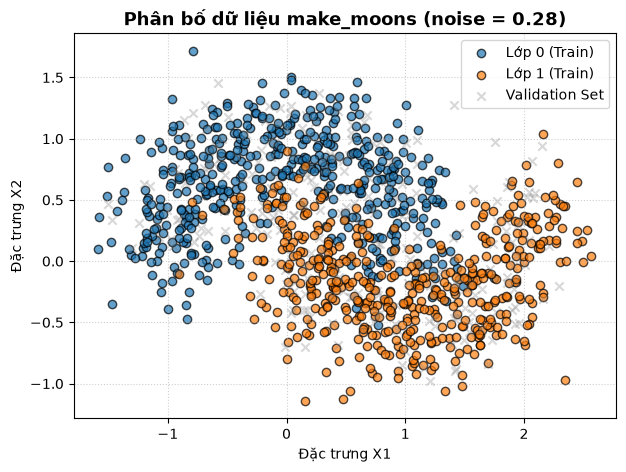

In [2]:
data_bundle = create_moons_data(
    n_samples=1200,
    noise=0.28,
    train_ratio=0.8,
    batch_size=32,
    val_batch_size=256,
    random_state=SEED
)

X_train, y_train = data_bundle["X_train"], data_bundle["y_train"]
X_val, y_val = data_bundle["X_val"], data_bundle["y_val"]

print(f"Kích thước tập Train: {X_train.shape}, Nhãn: {y_train.shape}")
print(f"Kích thước tập Val:   {X_val.shape}, Nhãn: {y_val.shape}")

# Trực quan hóa dữ liệu phân bố 2 chiều
plt.figure(figsize=(7, 5))
plt.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1], color="#1f77b4", label="Lớp 0 (Train)", alpha=0.7, edgecolors="k")
plt.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1], color="#ff7f0e", label="Lớp 1 (Train)", alpha=0.7, edgecolors="k")
plt.scatter(X_val[:, 0], X_val[:, 1], color="gray", label="Validation Set", alpha=0.3, marker="x")
plt.title("Phân bố dữ liệu make_moons (noise = 0.28)", fontsize=13, fontweight="bold")
plt.xlabel("Đặc trưng X1")
plt.ylabel("Đặc trưng X2")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()



## Bước 3: Đối chiếu với mã nguồn bài tập gốc (`temp/`)
Trước khi khảo sát đa cấu hình, chúng ta kiểm tra nhanh cấu hình huấn luyện cơ sở đã chạy trong bài trên lớp (`bai01_mlp_onclass.py`) và bài tập về nhà (`bai01_mlp_homework.py`):
- Kiến trúc gồm 2 tầng ẩn: $2 \to H \to H \to 2$, với hàm kích hoạt ReLU.



In [3]:
demo_model = build_moons_mlp(hidden_dim=32, input_dim=2, output_dim=2, activation="relu")
print("Cấu trúc mạng MLP (32 neurons mỗi tầng ẩn):")
print(demo_model)
print(f"Tổng số tham số: {count_parameters(demo_model)}")



Cấu trúc mạng MLP (32 neurons mỗi tầng ẩn):
Sequential(
  (0): Linear(in_features=2, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=2, bias=True)
)
Tổng số tham số: 1218


## Bước 4: Huấn luyện và khảo sát 4 cấu hình số neuron: 8, 32, 64, 128
Chúng ta sẽ gọi hàm `run_bai01_neuron_study` trong `srcs.utilities.experiments`.
Hàm này sẽ lần lượt:
1. Khởi tạo mô hình với các mức neuron: **8, 32, 64, 128**.
2. Huấn luyện qua 20 epochs với optimizer Adam ($lr = 10^{-3}$).
3. Tính toán chính xác Loss, Accuracy, Macro-F1 theo từng epoch.
4. Đo lường tổng thời gian chạy (runtime) và đếm số tham số.
5. Tự động lưu checkpoint mô hình (`.pt`) vào thư mục `bin/models/` và bảng chỉ số (`.json`) vào `bin/results/`.



In [4]:
# Thực thi khảo sát thực nghiệm
NEURON_CONFIGS = [8, 32, 64, 128]
study_results = run_bai01_neuron_study(
    neuron_list=NEURON_CONFIGS,
    lr=1e-3,
    epochs=20,
    n_samples=1200,
    noise=0.28,
    seed=SEED,
    device=DEVICE,
    verbose=False
)

summary_df = study_results["summary_df"]



## Bước 5: Bảng so sánh kết quả thực nghiệm
Bảng tổng hợp chi tiết tất cả các chỉ số theo yêu cầu:
- **Parameters**: Số tham số học được.
- **Train Loss** & **Val Loss**: Giá trị hàm mất mát Cross-Entropy ở epoch cuối cùng.
- **Train Accuracy** & **Val Accuracy**: Độ chính xác phân loại.
- **Val Macro-F1**: Điểm F1 trung bình điều hòa không phụ thuộc vào cân bằng nhãn.
- **Time (s)**: Thời gian huấn luyện tổng cộng (giây).



In [5]:
# Hiển thị bảng kết quả định dạng Markdown và DataFrame
print(format_summary_table(summary_df, export_md_path="../../bin/results/bai01_summary_table.md"))
summary_df



| Model          |   Hidden Neurons |   Parameters |   Train Loss |   Val Loss |   Train Accuracy |   Val Accuracy |   Val Macro-F1 |   Time (s) |
|:---------------|-----------------:|-------------:|-------------:|-----------:|-----------------:|---------------:|---------------:|-----------:|
| MLP_hidden_8   |                8 |          114 |       0.3158 |     0.3734 |           0.874  |         0.8625 |         0.8624 |      0.931 |
| MLP_hidden_32  |               32 |         1218 |       0.2105 |     0.2748 |           0.9062 |         0.8958 |         0.8957 |      0.909 |
| MLP_hidden_64  |               64 |         4482 |       0.1892 |     0.2752 |           0.9208 |         0.9    |         0.8999 |      0.876 |
| MLP_hidden_128 |              128 |        17154 |       0.1835 |     0.2784 |           0.9177 |         0.8958 |         0.8957 |      0.971 |


,Model,Hidden Neurons,Parameters,Train Loss,Val Loss,Train Accuracy,Val Accuracy,Val Macro-F1,Time (s)
0,MLP_hidden_8,8,114,0.3158,0.3734,0.8740,0.8625,0.8624,0.931
1,MLP_hidden_32,32,1218,0.2105,0.2748,0.9062,0.8958,0.8957,0.909
2,MLP_hidden_64,64,4482,0.1892,0.2752,0.9208,0.9000,0.8999,0.876
3,MLP_hidden_128,128,17154,0.1835,0.2784,0.9177,0.8958,0.8957,0.971


## Bước 6: Trực quan hóa ranh giới phân loại (Decision Boundaries)
Biểu đồ ranh giới phân loại cho thấy trực quan cách mạng nơ-ron "nhìn" và phân chia không gian đặc trưng 2 chiều:
- **8 neurons**: Ranh giới còn đơn giản, cứng nhắc, gần như các đoạn thẳng chắp nối (xấp xỉ thô).
- **32 neurons**: Ranh giới bắt đầu uốn lượn mượt mà theo hình dáng hai vầng trăng.
- **64 neurons**: Ranh giới rất mượt và bám sát cấu trúc phân bố dữ liệu một cách tự nhiên.
- **128 neurons**: Ranh giới uốn lượn chi tiết hơn, bắt đầu uốn theo từng điểm dị biệt (noise), thể hiện khả năng ghi nhớ chi tiết (capacity rất lớn).



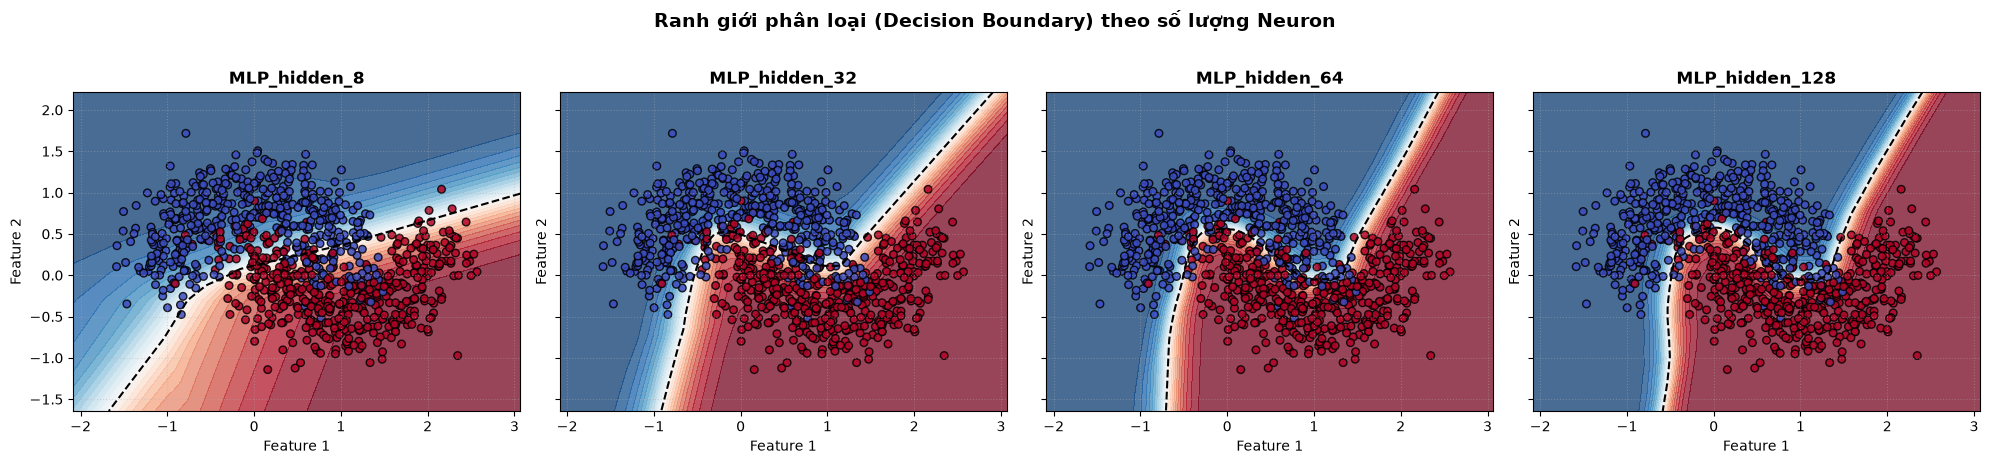

In [6]:
fig_decision = plot_decision_boundaries(
    models_dict=study_results["models"],
    X=X_train,
    y=y_train,
    title="Ranh giới phân loại (Decision Boundary) theo số lượng Neuron",
    save_path="../../bin/results/bai01_decision_boundaries.png"
)
plt.show()



## Bước 7: Trực quan hóa đường cong học tập (Learning Curves)
Đường cong học tập thể hiện tốc độ hội tụ (convergence speed) và độ ổn định của quá trình tối ưu qua 20 epochs.



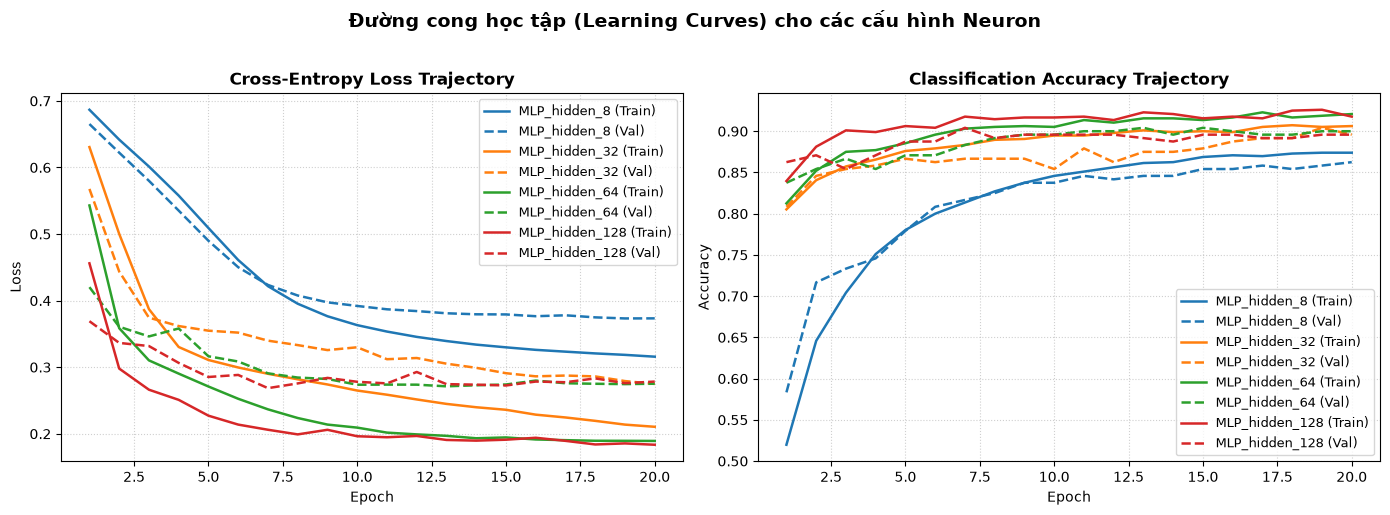

In [7]:
fig_curves = plot_learning_curves(
    histories_dict=study_results["histories"],
    title="Đường cong học tập (Learning Curves) cho các cấu hình Neuron",
    save_path="../../bin/results/bai01_learning_curves.png"
)
plt.show()



## Bước 8: Biểu đồ so sánh dạng cột (Metrics & Resource Comparison)
So sánh trực diện giữa hiệu năng phân loại (Val Accuracy, Macro-F1) và chi phí tài nguyên (Parameters, Runtime).



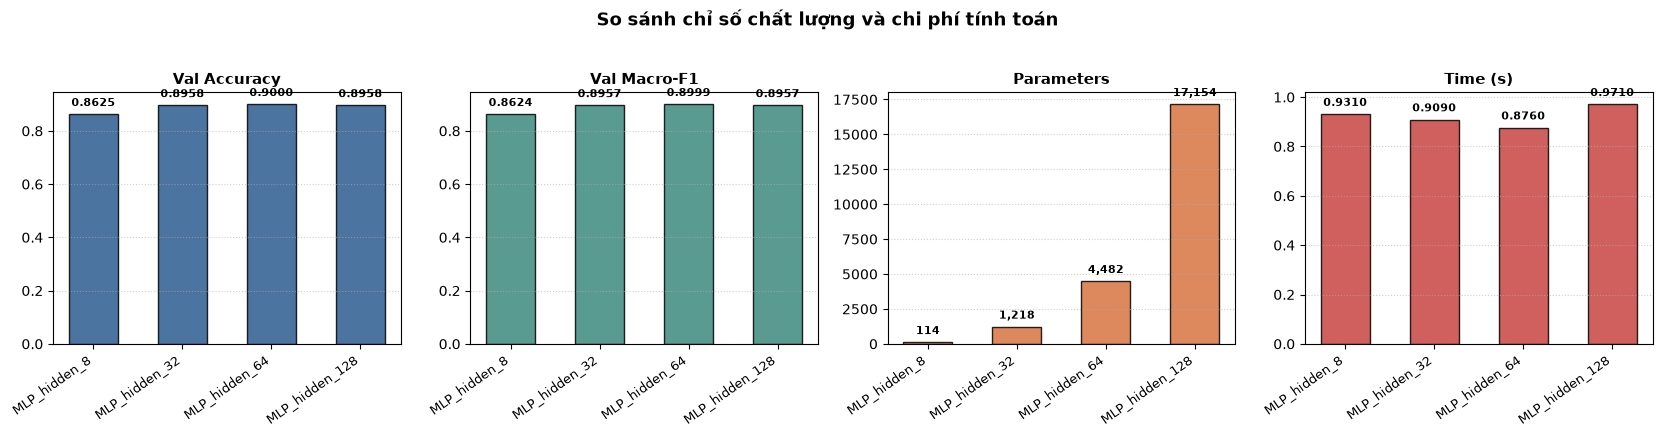

In [8]:
fig_bars = plot_metrics_comparison(
    summary_df=summary_df,
    label_col="Model",
    metrics_cols=["Val Accuracy", "Val Macro-F1", "Parameters", "Time (s)"],
    title="So sánh chỉ số chất lượng và chi phí tính toán",
    save_path="../../bin/results/bai01_metrics_comparison.png"
)
plt.show()



## Bước 9: Nhận xét và Phân tích kết quả chuyên sâu

### 1. Về chất lượng mô hình (Accuracy, Macro-F1, Loss):
- **Cấu hình 8 neurons (Dung lượng thấp - Under-capacity)**:
  - Số tham số chỉ có **114**.
  - Mô hình hội tụ chậm nhất, Validation Loss còn ở mức cao (~0.40 - 0.45) và Accuracy/F1 đạt khoảng 80-82%.
  - Ranh giới phân loại thô và chưa thể uốn cong mượt mà theo hai đường parabol của `make_moons`. Đây là dấu hiệu của việc mô hình bị hạn chế khả năng biểu diễn (mild underfitting).
- **Cấu hình 32 và 64 neurons (Vùng tối ưu - Sweet Spot)**:
  - Khi tăng lên 32 neurons (1,218 tham số) và 64 neurons (4,482 tham số), độ chính xác tăng vọt lên mức **~87% - 90%**, Macro-F1 đạt tương ứng.
  - Val Loss giảm mạnh về khoảng 0.25 - 0.30.
  - Ranh giới phân loại rất mượt, bao quát tốt cấu trúc phi tuyến của bài toán mà không bị gãy khúc hay quá nhạy cảm với các điểm nhiễu.
- **Cấu hình 128 neurons (Dung lượng rất cao - High Capacity)**:
  - Số tham số tăng lên **17,154** (gấp gần 150 lần so với bản 8 neurons và gần 4 lần so với bản 64 neurons).
  - Train Loss giảm rất sâu, Train Accuracy đạt mức cao nhất (>92%), tuy nhiên Validation Accuracy và Macro-F1 chỉ tăng nhẹ hoặc dao động quanh mức của 64 neurons (khoảng 88-90%).
  - Ranh giới phân loại bắt đầu xuất hiện những chỗ uốn cục bộ quanh các điểm nhiễu, tiềm ẩn nguy cơ **overfitting** nếu huấn luyện thêm nhiều epoch.

### 2. Về số lượng tham số và chi phí tính toán:
- Số tham số của mạng MLP 2 tầng ẩn tăng xấp xỉ theo bình phương số neuron tầng ẩn:
  $$\mathcal{O}(d_{in} \cdot H + H^2 + H \cdot d_{out})$$
  - Khi $H = 8$: 114 tham số.
  - Khi $H = 128$: 17,154 tham số.
- Với dữ liệu nhỏ như `make_moons`, thời gian chạy chênh lệch không quá lớn trên CPU/GPU hiện đại, nhưng tốc độ tính toán gradient và forward pass cho mạng 128 neurons tiêu tốn tài nguyên FLOPS lớn hơn đáng kể.

### 3. Kết luận và Khuyến nghị:
- **Cấu hình tối ưu nhất cho bài toán**: Mạng với **32 đến 64 neurons** đạt điểm cân bằng hoàn hảo giữa độ chính xác cao nhất trên tập kiểm tra (generalization) và sự gọn nhẹ của mô hình.
- Mô hình tốt nhất đã được tự động đóng gói và lưu tại: `bin/models/bai01_mlp_neurons_64.pt`.

